In [1]:

import random
import time


# 1. Algoritmo Guloso
def guloso(C):
    n = len(C)

    if n == 1:
        return {"custo": C[0], "caminho": [0]}

    # Escolhe a melhor cidade inicial
    if C[0] <= C[1]:
        atual = 0
    else:
        atual = 1

    caminho = [atual]
    custo = C[atual]

    # Avança até alcançar a última ou penúltima cidade
    while atual < n - 2:

        proxima = atual + 1
        seguinte = atual + 2

        if C[proxima] <= C[seguinte]:
            atual = proxima
        else:
            atual = seguinte

        caminho.append(atual)
        custo += C[atual]

    return {"custo": custo, "caminho": caminho}


# 2. Força-bruta
def forca_bruta(C):
    n = len(C)

    melhor_custo = float("inf")
    melhor_caminho = []

    def explorar(atual, custo, caminho):

        nonlocal melhor_custo, melhor_caminho

        # Chegou a uma das posições finais válidas
        if atual >= n - 2:
            if custo < melhor_custo:
                melhor_custo = custo
                melhor_caminho = caminho.copy()
            return

        # Tenta avançar uma cidade
        explorar(
            atual + 1,
            custo + C[atual + 1],
            caminho + [atual + 1]
        )

        # Tenta avançar duas cidades
        explorar(
            atual + 2,
            custo + C[atual + 2],
            caminho + [atual + 2]
        )

    # Pode começar na cidade 0 ou na cidade 1
    explorar(0, C[0], [0])
    explorar(1, C[1], [1])

    return {
        "custo": melhor_custo,
        "caminho": melhor_caminho
    }


# 3. Programação Dinâmica
def programacao_dinamica(C):
    n = len(C)

    dp = [0] * n
    predecessor = [-1] * n

    dp[0] = C[0]
    dp[1] = C[1]

    for i in range(2, n):

        if dp[i - 1] <= dp[i - 2]:
            dp[i] = C[i] + dp[i - 1]
            predecessor[i] = i - 1
        else:
            dp[i] = C[i] + dp[i - 2]
            predecessor[i] = i - 2

    # Escolhe o melhor destino
    if dp[n - 1] <= dp[n - 2]:
        atual = n - 1
    else:
        atual = n - 2

    melhor_custo = dp[atual]

    # Reconstrói o caminho
    caminho = []

    while atual != -1:
        caminho.append(atual)
        atual = predecessor[atual]

    caminho.reverse()

    return {
        "custo": melhor_custo,
        "caminho": caminho
    }


In [2]:
{
    "custo": 32,
    "caminho": [1, 3, 5]
}

{'custo': 32, 'caminho': [1, 3, 5]}

In [3]:

C = [10, 15, 20, 5, 8, 12]

print("Custos:", C)

print("\nGuloso:")
print(guloso(C))

print("\nForça-bruta:")
print(forca_bruta(C))

print("\nProgramação dinâmica:")
print(programacao_dinamica(C))


Custos: [10, 15, 20, 5, 8, 12]

Guloso:
{'custo': 38, 'caminho': [0, 1, 3, 4]}

Força-bruta:
{'custo': 28, 'caminho': [1, 3, 4]}

Programação dinâmica:
{'custo': 28, 'caminho': [1, 3, 4]}


In [4]:

def validar_solucao(C, resultado):

    n = len(C)

    caminho = resultado["caminho"]
    custo = resultado["custo"]

    # 1. Verifica se o caminho não está vazio
    if not caminho:
        return False, "Caminho vazio"

    # 2. Verifica a cidade inicial
    if caminho[0] not in [0, 1]:
        return False, "Cidade inicial inválida"

    # 3. Verifica se todas as cidades são válidas
    if any(i < 0 or i >= n for i in caminho):
        return False, "Cidade fora dos limites"

    # 4. Verifica os deslocamentos
    for i in range(len(caminho) - 1):

        deslocamento = caminho[i + 1] - caminho[i]

        if deslocamento not in [1, 2]:
            return False, "Deslocamento inválido"

    # 5. Verifica se chegou ao destino
    if caminho[-1] not in [n - 2, n - 1]:
        return False, "Destino não alcançado"

    # 6. Verifica se o custo está correto
    custo_calculado = sum(C[i] for i in caminho)

    if custo != custo_calculado:
        return False, "Custo informado incorreto"

    return True, "Solução válida"


In [5]:

C = [10, 15, 20, 5, 8, 12]

algoritmos = {
    "Guloso": guloso,
    "Força-bruta": forca_bruta,
    "Programação dinâmica": programacao_dinamica
}

for nome, algoritmo in algoritmos.items():

    resultado = algoritmo(C)

    valido, mensagem = validar_solucao(C, resultado)

    print(f"\n{nome}")
    print("Resultado:", resultado)
    print("Validação:", mensagem)



Guloso
Resultado: {'custo': 38, 'caminho': [0, 1, 3, 4]}
Validação: Solução válida

Força-bruta
Resultado: {'custo': 28, 'caminho': [1, 3, 4]}
Validação: Solução válida

Programação dinâmica
Resultado: {'custo': 28, 'caminho': [1, 3, 4]}
Validação: Solução válida


In [6]:

import random

random.seed(42)

quantidade_testes = 1000

erros_validacao = 0
erros_otimalidade = 0

for teste in range(quantidade_testes):

    n = random.randint(2, 15)

    C = [
        random.randint(1, 100)
        for _ in range(n)
    ]

    resultado_guloso = guloso(C)
    resultado_bruta = forca_bruta(C)
    resultado_dp = programacao_dinamica(C)

    # Validação dos caminhos
    for resultado in [
        resultado_guloso,
        resultado_bruta,
        resultado_dp
    ]:

        valido, mensagem = validar_solucao(C, resultado)

        if not valido:
            erros_validacao += 1
            print("Erro de validação:", C, resultado, mensagem)

    # Comparação da solução ótima
    if resultado_bruta["custo"] != resultado_dp["custo"]:

        erros_otimalidade += 1

        print("Divergência encontrada!")
        print("Vetor:", C)
        print("Força-bruta:", resultado_bruta)
        print("Programação dinâmica:", resultado_dp)


print("\n========== RESULTADO DOS TESTES ==========")
print("Total de testes:", quantidade_testes)
print("Erros de validação:", erros_validacao)
print("Erros de otimalidade:", erros_otimalidade)



========== RESULTADO DOS TESTES ==========
Total de testes: 1000
Erros de validação: 0
Erros de otimalidade: 0


In [7]:
import time
import random
from statistics import mean

SEMENTE = 42
REPETICOES = 30
def gerar_entradas(tamanhos, repeticoes=30, seed=42):

    rng = random.Random(seed)

    entradas = {}

    for n in tamanhos:

        entradas[n] = []

        for _ in range(repeticoes):

            C = [
                rng.randint(1, 100)
                for _ in range(n)
            ]

            entradas[n].append(C)

    return entradas


# Tamanhos dos experimentos
tamanhos_tres = [5, 10, 15, 20, 22, 24, 26]

tamanhos_lineares = [
    100, 500, 1000, 5000, 10000, 50000
]


# Geramos os vetores uma única vez
entradas_tres = gerar_entradas(
    tamanhos_tres,
    REPETICOES,
    SEMENTE
)

entradas_lineares = gerar_entradas(
    tamanhos_lineares,
    REPETICOES,
    SEMENTE
)

print("Entradas geradas!")

for n in tamanhos_tres:
    print(f"n={n}: {len(entradas_tres[n])} vetores")

Entradas geradas!
n=5: 30 vetores
n=10: 30 vetores
n=15: 30 vetores
n=20: 30 vetores
n=22: 30 vetores
n=24: 30 vetores
n=26: 30 vetores


In [8]:
def executar_benchmark(entradas, algoritmos, repeticoes_medicao=5):

    resultados = {}

    rng_ordem = random.Random(123)

    for n, vetores in entradas.items():

        resultados[n] = {}

        for nome in algoritmos:
            resultados[n][nome] = []

        for C in vetores:

            # Embaralha a ordem de execução
            ordem = list(algoritmos.keys())
            rng_ordem.shuffle(ordem)

            for nome in ordem:

                algoritmo = algoritmos[nome]

                # Mede várias execuções da mesma entrada
                inicio = time.perf_counter_ns()

                for _ in range(repeticoes_medicao):
                    resultado = algoritmo(C)

                fim = time.perf_counter_ns()

                # Tempo médio por execução, em segundos
                tempo = (
                    (fim - inicio)
                    / repeticoes_medicao
                    / 1e9
                )

                resultados[n][nome].append(tempo)

                # Validação fora da medição
                valido, mensagem = validar_solucao(
                    C, resultado
                )

                if not valido:
                    raise ValueError(
                        f"Erro em {nome}, n={n}: {mensagem}"
                    )

        print(f"n={n} concluído!")

    return resultados

In [9]:
# Grupo A: três algoritmos
algoritmos_completos = {
    "Guloso": guloso,
    "Força-bruta": forca_bruta,
    "Programação dinâmica": programacao_dinamica
}

# Grupo B: algoritmos lineares
algoritmos_lineares = {
    "Guloso": guloso,
    "Programação dinâmica": programacao_dinamica
}

In [10]:
# Grupo A: comparação dos três algoritmos
resultados_tres = executar_benchmark(
    entradas_tres,
    algoritmos_completos
)

# Grupo B: comparação dos algoritmos lineares
resultados_lineares = executar_benchmark(
    entradas_lineares,
    algoritmos_lineares
)

n=5 concluído!
n=10 concluído!
n=15 concluído!
n=20 concluído!
n=22 concluído!
n=24 concluído!
n=26 concluído!
n=100 concluído!
n=500 concluído!
n=1000 concluído!
n=5000 concluído!
n=10000 concluído!
n=50000 concluído!


In [11]:
print("\n===== GRUPO A =====")

for n, algoritmos in resultados_tres.items():

    print(f"\nn = {n}")

    for nome, tempos in algoritmos.items():

        print(
            f"{nome}: {mean(tempos):.10f} segundos"
        )


print("\n===== GRUPO B =====")

for n, algoritmos in resultados_lineares.items():

    print(f"\nn = {n}")

    for nome, tempos in algoritmos.items():

        print(
            f"{nome}: {mean(tempos):.10f} segundos"
        )


===== GRUPO A =====

n = 5
Guloso: 0.0000004700 segundos
Força-bruta: 0.0000294473 segundos
Programação dinâmica: 0.0000009740 segundos

n = 10
Guloso: 0.0000008093 segundos
Força-bruta: 0.0000309340 segundos
Programação dinâmica: 0.0000016547 segundos

n = 15
Guloso: 0.0000011193 segundos
Força-bruta: 0.0003422693 segundos
Programação dinâmica: 0.0000021900 segundos

n = 20
Guloso: 0.0000017033 segundos
Força-bruta: 0.0038877427 segundos
Programação dinâmica: 0.0000034693 segundos

n = 22
Guloso: 0.0000017260 segundos
Força-bruta: 0.0101252280 segundos
Programação dinâmica: 0.0000035227 segundos

n = 24
Guloso: 0.0000018987 segundos
Força-bruta: 0.0267546753 segundos
Programação dinâmica: 0.0000038907 segundos

n = 26
Guloso: 0.0000020520 segundos
Força-bruta: 0.0713716380 segundos
Programação dinâmica: 0.0000039513 segundos

===== GRUPO B =====

n = 100
Guloso: 0.0000059627 segundos
Programação dinâmica: 0.0000109760 segundos

n = 500
Guloso: 0.0000333200 segundos
Programação dinâmi

In [12]:
# Tempos do guloso para n = 10
resultados_tres[10]["Guloso"]

# Tempos da força-bruta para n = 20
resultados_tres[20]["Força-bruta"]

# Tempos da programação dinâmica para n = 5000
resultados_lineares[5000]["Programação dinâmica"]

[0.0006786,
 0.00067816,
 0.0006938,
 0.00066998,
 0.0006653,
 0.00068382,
 0.00067902,
 0.00077064,
 0.00067874,
 0.00067626,
 0.00068306,
 0.00068032,
 0.00070702,
 0.00068406,
 0.00068252,
 0.001191,
 0.00119152,
 0.00085242,
 0.00065466,
 0.0006517,
 0.00076994,
 0.00067686,
 0.00067594,
 0.00067626,
 0.00067318,
 0.00072158,
 0.00117106,
 0.0008302,
 0.00065558,
 0.00070592]

In [13]:
import pandas as pd
from statistics import mean, stdev

def gerar_tabela_resultados(resultados):

    dados = []

    for n, algoritmos in resultados.items():

        for nome, tempos in algoritmos.items():

            dados.append({
                "Tamanho (n)": n,
                "Algoritmo": nome,
                "Tempo médio (s)": mean(tempos),
                "Desvio padrão (s)": stdev(tempos)
            })

    return pd.DataFrame(dados)


df_tres = gerar_tabela_resultados(resultados_tres)
df_lineares = gerar_tabela_resultados(resultados_lineares)

display(df_tres)
display(df_lineares)

,Tamanho (n),Algoritmo,Tempo médio (s),Desvio padrão (s)
0,5,Guloso,4.700000e-07,7.696842e-08
1,5,Força-bruta,2.944733e-05,1.408141e-04
2,5,Programação dinâmica,9.740000e-07,2.061904e-07
3,10,Guloso,8.093333e-07,1.435254e-07
4,10,Força-bruta,3.093400e-05,3.764114e-06
5,10,Programação dinâmica,1.654667e-06,6.358038e-07
6,15,Guloso,1.119333e-06,1.152489e-07
7,15,Força-bruta,3.422693e-04,3.778218e-05
8,15,Programação dinâmica,2.190000e-06,3.243136e-07
9,20,Guloso,1.703333e-06,3.036370e-07


,Tamanho (n),Algoritmo,Tempo médio (s),Desvio padrão (s)
0,100,Guloso,0.000006,2.245445e-07
1,100,Programação dinâmica,0.000011,3.651509e-07
2,500,Guloso,0.000033,2.255910e-06
3,500,Programação dinâmica,0.000061,1.557885e-06
4,1000,Guloso,0.000069,5.270495e-06
5,1000,Programação dinâmica,0.000131,1.366646e-05
6,5000,Guloso,0.000375,7.821027e-05
7,5000,Programação dinâmica,0.000747,1.557836e-04
8,10000,Guloso,0.000706,4.172132e-05
9,10000,Programação dinâmica,0.001391,5.532946e-05


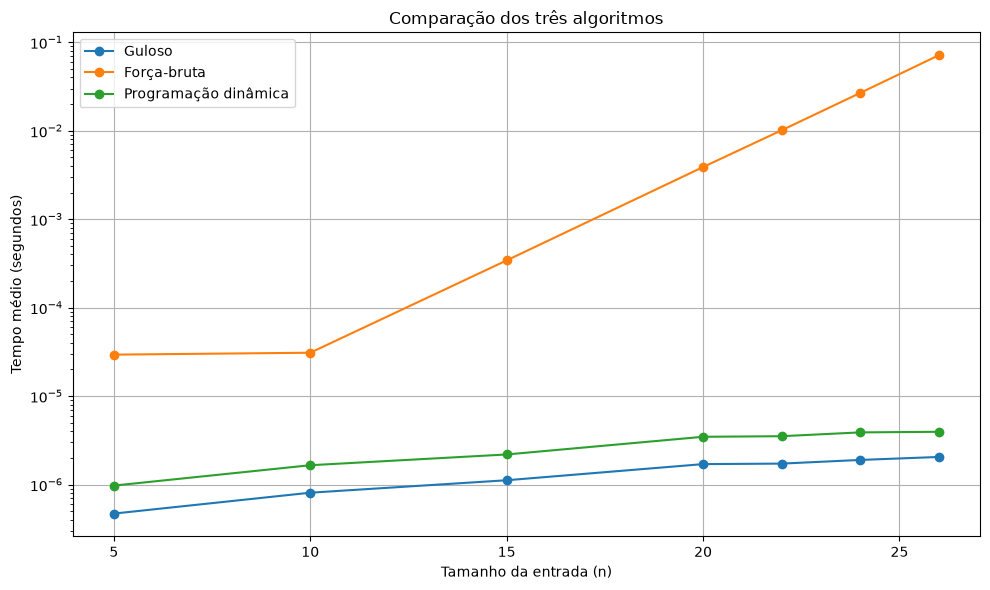

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for algoritmo in df_tres["Algoritmo"].unique():

    dados = df_tres[
        df_tres["Algoritmo"] == algoritmo
    ]

    plt.plot(
        dados["Tamanho (n)"],
        dados["Tempo médio (s)"],
        marker="o",
        label=algoritmo
    )

plt.xlabel("Tamanho da entrada (n)")
plt.ylabel("Tempo médio (segundos)")
plt.title("Comparação dos três algoritmos")
plt.yscale("log")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

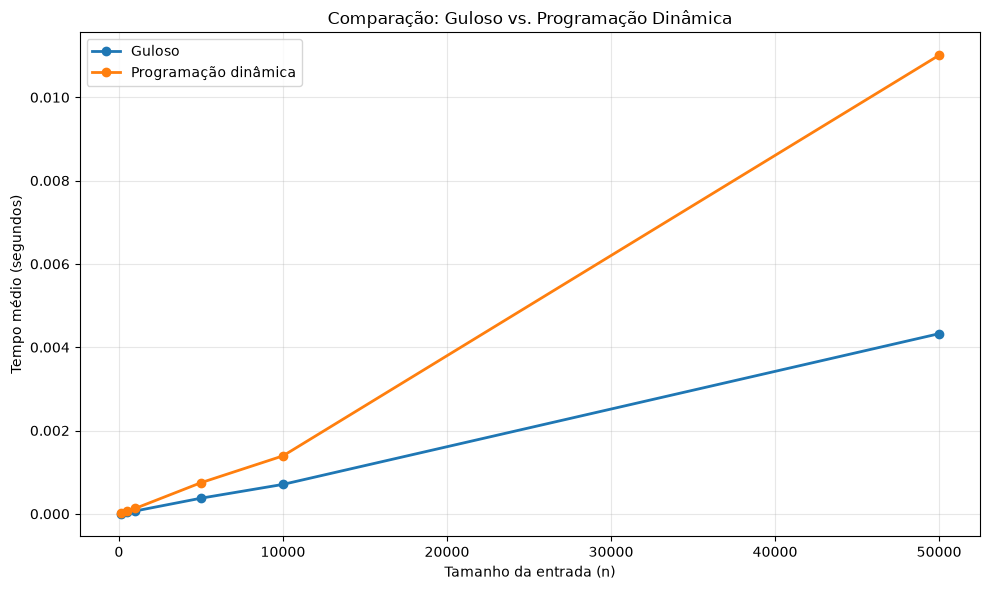

In [15]:

import matplotlib.pyplot as plt
from statistics import mean

plt.figure(figsize=(10, 6))

for algoritmo in resultados_lineares[100].keys():

    tamanhos = []
    tempos = []

    for n, resultados in resultados_lineares.items():

        tamanhos.append(n)
        tempos.append(mean(resultados[algoritmo]))

    plt.plot(
        tamanhos,
        tempos,
        marker="o",
        linewidth=2,
        label=algoritmo
    )

plt.xlabel("Tamanho da entrada (n)")
plt.ylabel("Tempo médio (segundos)")
plt.title("Comparação: Guloso vs. Programação Dinâmica")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()


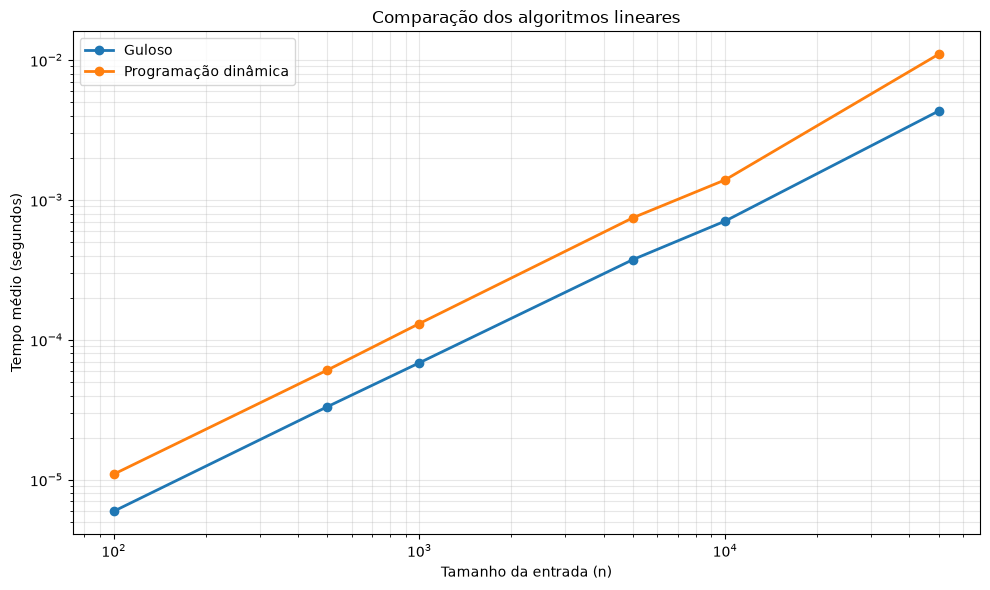

In [16]:
plt.figure(figsize=(10, 6))

for algoritmo in resultados_lineares[100].keys():

    tamanhos = list(resultados_lineares.keys())

    tempos = [
        mean(resultados_lineares[n][algoritmo])
        for n in tamanhos
    ]

    plt.plot(
        tamanhos,
        tempos,
        marker="o",
        linewidth=2,
        label=algoritmo
    )

plt.xlabel("Tamanho da entrada (n)")
plt.ylabel("Tempo médio (segundos)")
plt.title("Comparação dos algoritmos lineares")

plt.xscale("log")
plt.yscale("log")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:

from statistics import mean

def calcular_tempo_total(resultados, repeticoes_medicao=5):

    totais = {}

    for n, algoritmos in resultados.items():

        for nome, tempos in algoritmos.items():

            if nome not in totais:
                totais[nome] = 0

            # Cada tempo armazenado é a média de 5 execuções
            totais[nome] += sum(tempos) * repeticoes_medicao

    return totais


total_tres = calcular_tempo_total(resultados_tres)
total_lineares = calcular_tempo_total(resultados_lineares)

print("===== TEMPO TOTAL - GRUPO A =====")

for nome, tempo in total_tres.items():
    print(f"{nome}: {tempo:.8f} segundos")


print("\n===== TEMPO TOTAL - GRUPO B =====")

for nome, tempo in total_lineares.items():
    print(f"{nome}: {tempo:.8f} segundos")


===== TEMPO TOTAL - GRUPO A =====
Guloso: 0.00146680 segundos
Força-bruta: 16.88129020 segundos
Programação dinâmica: 0.00294790 segundos

===== TEMPO TOTAL - GRUPO B =====
Guloso: 0.82712280 segundos
Programação dinâmica: 2.00253890 segundos


In [21]:


import pandas as pd

def analisar_qualidade(entradas):

    resultados = []

    for n, vetores in entradas.items():

        acertos_guloso = 0
        diferencas = []
        gaps_relativos = []
        custos_otimos = []

        for C in vetores:

            r_guloso = guloso(C)
            r_bruta = forca_bruta(C)
            r_dp = programacao_dinamica(C)

            # Confirma que força-bruta e DP concordam
            assert r_bruta["custo"] == r_dp["custo"]

            otimo = r_bruta["custo"]
            custo_guloso = r_guloso["custo"]

            # Verifica se o guloso encontrou a solução ótima
            if custo_guloso == otimo:
                acertos_guloso += 1

            # Diferença absoluta de custo
            diferencas.append(custo_guloso - otimo)

            # Gap relativo em porcentagem
            gap = ((custo_guloso - otimo) / otimo) * 100
            gaps_relativos.append(gap)

            # Armazena o custo ótimo
            custos_otimos.append(otimo)

        resultados.append({
            "Tamanho": n,
            "Total de entradas": len(vetores),
            "Acertos do guloso": acertos_guloso,
            "Taxa de otimalidade (%)": (
                acertos_guloso / len(vetores) * 100
            ),
            "Custo ótimo médio": sum(custos_otimos) / len(custos_otimos),
            "Diferença média de custo": sum(diferencas) / len(diferencas),
            "Gap relativo médio (%)": sum(gaps_relativos) / len(gaps_relativos)
        })

    return pd.DataFrame(resultados)


# Executa a análise
df_qualidade = analisar_qualidade(entradas_tres)

display(df_qualidade)


,Tamanho,Total de entradas,Acertos do guloso,Taxa de otimalidade (%),Custo ótimo médio,Diferença média de custo,Gap relativo médio (%)
0,5,30,16,53.333333,84.766667,10.000000,10.814320
1,10,30,9,30.000000,188.866667,27.566667,14.481695
2,15,30,7,23.333333,311.533333,43.100000,12.979401
3,20,30,2,6.666667,418.933333,58.500000,13.810782
4,22,30,2,6.666667,463.333333,68.866667,14.201837
5,24,30,1,3.333333,517.166667,71.733333,13.875005
6,26,30,2,6.666667,548.233333,85.666667,15.030380


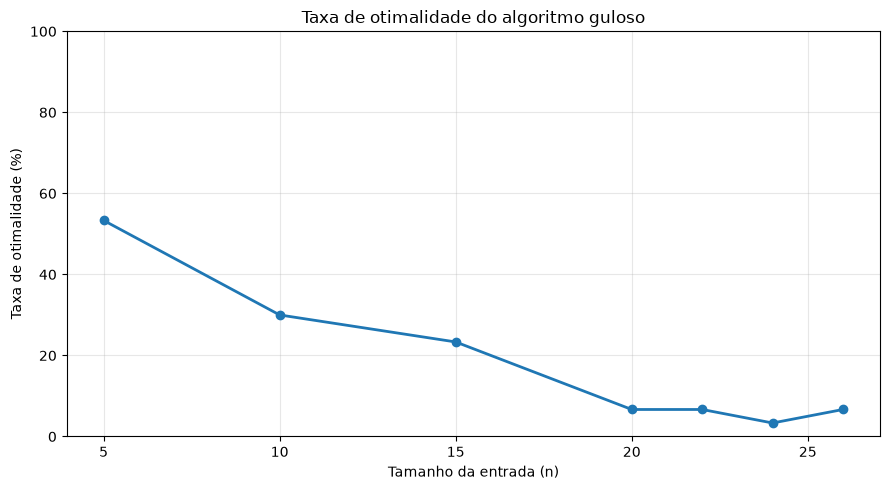

In [20]:

plt.figure(figsize=(9, 5))

plt.plot(
    df_qualidade["Tamanho"],
    df_qualidade["Taxa de otimalidade (%)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Tamanho da entrada (n)")
plt.ylabel("Taxa de otimalidade (%)")
plt.title("Taxa de otimalidade do algoritmo guloso")

plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


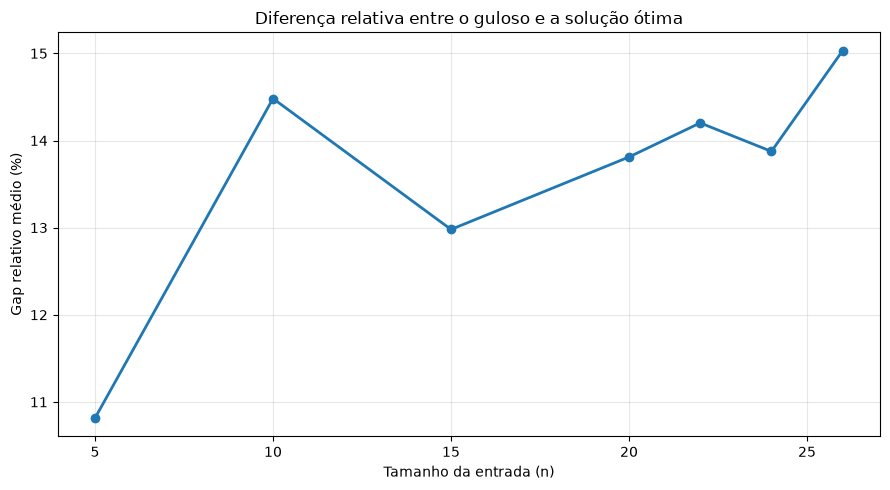

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(
    df_qualidade["Tamanho"],
    df_qualidade["Gap relativo médio (%)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Tamanho da entrada (n)")
plt.ylabel("Gap relativo médio (%)")
plt.title("Diferença relativa entre o guloso e a solução ótima")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()